<a href="https://colab.research.google.com/github/MuhammadRayan07/Weather-Analysis/blob/main/notebooks/02_Analysis_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
BASE = Path("/content/drive/MyDrive/weather-analysis")
PROCESSED = BASE / "data" / "processed"

weather = pd.read_csv(PROCESSED / "weather_combined.csv", parse_dates=["date", "collected_at"])
print(weather.shape)

Mounted at /content/drive
(73060, 24)


In [3]:
SEED = 15
np.random.seed(SEED)
results_log = []

# 4. Dataset Understanding and Description

## 4.1

In [4]:
weather.head()


,city,country,latitude,longitude,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,...,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,surface_pressure_mean,collected_at
0,Lahore,Pakistan,31.5497,74.3436,2016-01-01,3,20.9,8.9,14.5,0.0,...,340,10.82,35639.67,36470.50,64,7.2,46,1021.0,994.5,2026-11-22 14:39:52+00:00
1,Lahore,Pakistan,31.5497,74.3436,2016-01-02,3,20.6,6.2,13.0,0.0,...,351,12.30,35442.13,36500.41,69,6.8,37,1021.9,995.3,2026-11-22 14:39:52+00:00
2,Lahore,Pakistan,31.5497,74.3436,2016-01-03,3,21.6,7.5,14.1,0.0,...,298,12.20,35613.56,36532.97,65,6.9,34,1018.7,992.3,2026-11-22 14:39:52+00:00
3,Lahore,Pakistan,31.5497,74.3436,2016-01-04,51,20.9,9.5,14.6,0.6,...,99,9.30,28133.52,36568.10,73,9.5,63,1018.7,992.3,2026-11-22 14:39:52+00:00
4,Lahore,Pakistan,31.5497,74.3436,2016-01-05,3,21.9,8.8,14.8,0.0,...,354,12.77,35593.52,36605.75,77,10.3,27,1018.6,992.2,2026-11-22 14:39:52+00:00


In [5]:
weather.tail()

,city,country,latitude,longitude,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,...,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,surface_pressure_mean,collected_at
73055,Sao Paulo,Brazil,-23.5505,-46.6333,2025-12-27,63,35.6,22.6,27.1,4.4,...,356,26.75,47943.35,48864.91,66,19.7,51,1013.6,930.5,2026-11-22 15:03:58+00:00
73056,Sao Paulo,Brazil,-23.5505,-46.6333,2025-12-28,65,35.0,23.1,27.9,13.2,...,208,27.64,48255.21,48852.27,61,18.9,48,1012.0,929.2,2026-11-22 15:03:58+00:00
73057,Sao Paulo,Brazil,-23.5505,-46.6333,2025-12-29,63,33.6,22.6,26.2,5.0,...,344,27.59,46254.16,48837.74,71,19.9,69,1012.0,928.8,2026-11-22 15:03:58+00:00
73058,Sao Paulo,Brazil,-23.5505,-46.6333,2025-12-30,63,31.4,20.9,24.9,8.0,...,350,27.12,46018.42,48821.30,78,20.5,71,1013.0,929.3,2026-11-22 15:03:58+00:00
73059,Sao Paulo,Brazil,-23.5505,-46.6333,2025-12-31,63,29.7,20.1,23.9,8.0,...,320,22.06,37814.08,48802.99,81,20.1,80,1013.9,929.9,2026-11-22 15:03:58+00:00


head() and tail() show the first and last 5 rows

## 4.2

In [6]:
rows, cols = weather.shape
print(f"Rows: {rows:,} | Columns: {cols}")
print(weather.columns.tolist())

Rows: 73,060 | Columns: 24
['city', 'country', 'latitude', 'longitude', 'date', 'weather_code', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'sunshine_duration', 'daylight_duration', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'pressure_msl_mean', 'surface_pressure_mean', 'collected_at']


shape returns a (rows, columns) pair,

## 4.3

In [7]:
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73060 entries, 0 to 73059
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype              
---  ------                       --------------  -----              
 0   city                         73060 non-null  object             
 1   country                      73060 non-null  object             
 2   latitude                     73060 non-null  float64            
 3   longitude                    73060 non-null  float64            
 4   date                         73060 non-null  datetime64[ns]     
 5   weather_code                 73060 non-null  int64              
 6   temperature_2m_max           73060 non-null  float64            
 7   temperature_2m_min           73060 non-null  float64            
 8   temperature_2m_mean          73060 non-null  float64            
 9   precipitation_sum            73060 non-null  float64            
 10  rain_sum                     73060 non-null  f

info() prints each column's name, non-null count, and data type, plus total memory

## 4.4

In [8]:
location_cols    = ["city", "country", "latitude", "longitude"]
date_cols        = ["date"]
categorical_cols = ["city", "country", "weather_code"]
boolean_cols     = []
numeric_cols = [c for c in weather.columns
                if c not in location_cols + date_cols + ["weather_code", "collected_at"]]

print("Location   :", location_cols)
print("Date       :", date_cols)
print("Categorical:", categorical_cols)
print("Boolean    :", boolean_cols, "(none yet; the rainy-day target will be created later)")
print("Numerical  :", numeric_cols)

Location   : ['city', 'country', 'latitude', 'longitude']
Date       : ['date']
Categorical: ['city', 'country', 'weather_code']
Boolean    : [] (none yet; the rainy-day target will be created later)
Numerical  : ['temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'sunshine_duration', 'daylight_duration', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'pressure_msl_mean', 'surface_pressure_mean']


Identifying numerical, categorical, Boolean, date-related, and location variables.collected_at is not a weather feature, so it's excluded from analysis and modeling

## 4.5

In [9]:
weather[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,73060.0,22.494370,10.121488,-26.20,16.6000,24.200,29.7000,47.30
temperature_2m_min,73060.0,13.570739,9.414030,-31.10,7.8000,14.100,21.2000,34.40
temperature_2m_mean,73060.0,17.802529,9.482271,-28.50,12.3000,18.700,25.5000,39.70
precipitation_sum,73060.0,2.658535,6.704097,0.00,0.0000,0.100,2.2000,304.90
rain_sum,73060.0,2.559214,6.637615,0.00,0.0000,0.000,1.9000,304.90
precipitation_hours,73060.0,3.902833,5.531370,0.00,0.0000,1.000,7.0000,24.00
wind_speed_10m_max,73060.0,19.019704,7.401118,3.40,13.6000,17.900,23.0000,95.90
wind_gusts_10m_max,73060.0,38.094656,14.748277,7.20,28.4000,35.600,43.9000,190.10
wind_direction_10m_dominant,73060.0,192.489666,105.191564,0.00,103.0000,208.000,282.0000,360.00
shortwave_radiation_sum,73060.0,16.196337,7.345812,0.01,11.1200,17.030,21.6300,34.53


describe() gives count, mean, std, min, quartiles (25%, 50%, 75%) and max for each numerical column

## 4.6

In [10]:
for col in categorical_cols:
    print(f"\n{col}: {weather[col].nunique()} unique values")
    print(weather[col].value_counts())


city: 20 unique values
city
Lahore         3653
Karachi        3653
Dubai          3653
Delhi          3653
Tokyo          3653
Singapore      3653
Beijing        3653
Sydney         3653
Cairo          3653
Nairobi        3653
Lagos          3653
Cape Town      3653
London         3653
Paris          3653
Moscow         3653
Reykjavik      3653
New York       3653
Toronto        3653
Mexico City    3653
Sao Paulo      3653
Name: count, dtype: int64

country: 19 unique values
country
Pakistan        7306
UAE             3653
India           3653
Japan           3653
Singapore       3653
China           3653
Australia       3653
Egypt           3653
Kenya           3653
Nigeria         3653
South Africa    3653
UK              3653
France          3653
Russia          3653
Iceland         3653
USA             3653
Canada          3653
Mexico          3653
Brazil          3653
Name: count, dtype: int64

weather_code: 13 unique values
weather_code
3     22190
51    13684
0      6753
63  

Identifying unique values and frequency distributions for categorical variables.
nunique() counts distinct values, and value_counts() counts how many rows each value has

## 4.7

In [11]:
mem_mb = weather.memory_usage(deep=True).sum() / 1024**2
print(f"Memory usage: {mem_mb:.2f} MB")

Memory usage: 20.00 MB


memory_usage(deep=True) measures bytes per column .sum() adds them up and dividing by 1024**2 converts bytes to megabytes.

## 4.8

In [12]:
missing = weather.isnull().sum()
missing_report = pd.DataFrame({"missing_count": missing,"missing_percent": (missing / len(weather) * 100).round(2)})
missing_report

,missing_count,missing_percent
city,0,0.0
country,0,0.0
latitude,0,0.0
longitude,0,0.0
date,0,0.0
weather_code,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
temperature_2m_mean,0,0.0
precipitation_sum,0,0.0


In [13]:
missing_by_city = weather.isnull().groupby(weather["city"]).sum().sum(axis=1)
missing_by_year = weather.isnull().groupby(weather["date"].dt.year).sum().sum(axis=1)
print(missing_by_city[missing_by_city > 0])
print(missing_by_year[missing_by_year > 0])

Series([], dtype: int64)
Series([], dtype: int64)


We need to find missing values in each column and inspect missingness by city and date.
Here
->isnull() creates a True/False table and .sum() counts the Trues per column.
->groupby(weather["city"]) splits the True/False table by city
weather["date"].dt.year extracts the year from a datetime column.

## 4.9

In [14]:
print("Fully duplicated rows:", weather.duplicated().sum())
print("Repeated city-date pairs:", weather.duplicated(subset=["city", "date"]).sum())

Fully duplicated rows: 0
Repeated city-date pairs: 0


# 5. Data Cleaning and Preprocessing

## A. Missing values and duplicates

## 1.

Cell 4.8 (the missing_report table) which showed 0 missing values and 0.0% for all 23 columns

## 2.

In [15]:
df = weather.sort_values(["city", "date"]).reset_index(drop=True)

df["is_rainy"] = (df["precipitation_sum"] > 0).astype(int)

df["target_tmax_next"] = df.groupby("city")["temperature_2m_max"].shift(-1)

lag_cols = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
            "precipitation_sum", "wind_speed_10m_max", "relative_humidity_2m_mean",
            "dew_point_2m_mean", "cloud_cover_mean", "pressure_msl_mean",
            "shortwave_radiation_sum"]
for c in lag_cols:
    df[f"{c}_lag1"] = df.groupby("city")[c].shift(1)

before = len(df)
lag_names = [f"{c}_lag1" for c in lag_cols]
df = df.dropna(subset=["target_tmax_next"] + lag_names).reset_index(drop=True)
print(f"Rows before: {before:,} | after: {len(df):,} | dropped: {before - len(df)}")

print(df["is_rainy"].value_counts())
print(df["is_rainy"].value_counts(normalize=True).round(3))

Rows before: 73,060 | after: 73,020 | dropped: 40
is_rainy
1    37357
0    35663
Name: count, dtype: int64
is_rainy
1    0.512
0    0.488
Name: proportion, dtype: float64


The models will predict the next-day maximum temperature and whether a day is rainy, using the previous-day features.I sorted the data by city and date, then created the classification target 'is_rainy' (1 if precipitation is above zero) and the regression target 'target_tmax_next'Rows without a valid previous-day or next-day value were dropped

## 3. and 4.

In [16]:
df_missing = df.copy()

same_day_cols = ["temperature_2m_min", "temperature_2m_mean", "wind_speed_10m_max",
                 "wind_gusts_10m_max", "wind_direction_10m_dominant",
                 "shortwave_radiation_sum", "sunshine_duration",
                 "relative_humidity_2m_mean", "dew_point_2m_mean",
                 "cloud_cover_mean", "pressure_msl_mean", "surface_pressure_mean"]
missing_cols = same_day_cols + lag_names

df_missing[missing_cols] = df_missing[missing_cols].astype(float)

rng = np.random.default_rng(SEED)
for col in missing_cols:
    mask = rng.random(len(df_missing)) < 0.05
    df_missing.loc[mask, col] = np.nan

report = pd.DataFrame({
    "missing_count": df_missing[missing_cols].isnull().sum(),
    "missing_percent": (df_missing[missing_cols].isnull().mean() * 100).round(2)
})
print(report)
#5A-4
protected = ["is_rainy", "target_tmax_next", "temperature_2m_max", "precipitation_sum"]
print("\nMissing values in protected columns:")
print(df_missing[protected].isnull().sum())

df_missing.to_csv(PROCESSED / "weather_with_missing.csv", index=False)

                                missing_count  missing_percent
temperature_2m_min                       3611             4.95
temperature_2m_mean                      3728             5.11
wind_speed_10m_max                       3736             5.12
wind_gusts_10m_max                       3665             5.02
wind_direction_10m_dominant              3610             4.94
shortwave_radiation_sum                  3690             5.05
sunshine_duration                        3709             5.08
relative_humidity_2m_mean                3598             4.93
dew_point_2m_mean                        3673             5.03
cloud_cover_mean                         3677             5.04
pressure_msl_mean                        3769             5.16
surface_pressure_mean                    3663             5.02
temperature_2m_max_lag1                  3654             5.00
temperature_2m_min_lag1                  3645             4.99
temperature_2m_mean_lag1                 3690          

The real data has no missing values, so I made a separate copy, `df_missing`, and randomly blanked about 5% of the cells in 22 input-feature columns, using SEED = 15 so the result is reproducible.

## 6.

Duplicate records (0) and repeated combinations of city-date were identified in section 4.9

### 7.

In [17]:
print("rain_sum > precipitation_sum :", (weather["rain_sum"] > weather["precipitation_sum"] + 1e-6).sum())
print("sunshine > daylight          :", (weather["sunshine_duration"] > weather["daylight_duration"]).sum())
print("temp ordering violated       :", ((weather["temperature_2m_min"] > weather["temperature_2m_mean"]) |
                                         (weather["temperature_2m_mean"] > weather["temperature_2m_max"])).sum())

print("negative precipitation       :", (weather[["precipitation_sum","rain_sum","precipitation_hours"]] < 0).sum().sum())
print("humidity outside 0-100       :", (~weather["relative_humidity_2m_mean"].between(0, 100)).sum())
print("cloud cover outside 0-100    :", (~weather["cloud_cover_mean"].between(0, 100)).sum())
print("wind direction outside 0-360 :", (~weather["wind_direction_10m_dominant"].between(0, 360)).sum())
print("precip hours above 24        :", (weather["precipitation_hours"] > 24).sum())

gaps = weather.sort_values(["city", "date"]).groupby("city")["date"].diff().dt.days
print("max gap between consecutive dates:", gaps.max())

print(weather.groupby("city")[["country", "latitude", "longitude"]].nunique().max())

rain_sum > precipitation_sum : 0
sunshine > daylight          : 0
temp ordering violated       : 0
negative precipitation       : 0
humidity outside 0-100       : 0
cloud cover outside 0-100    : 0
wind direction outside 0-360 : 0
precip hours above 24        : 0
max gap between consecutive dates: 1.0
country      1
latitude     1
longitude    1
dtype: int64


Checked the data for impossible or inconsistent values, date gaps, and mismatched city identifiers.

-> The data has no nulls, but values can still be physically impossible or dates can be skipped, which would corrupt the lag features and models.

# 10. Train-Test Split and Validation

Section 10 says to fit imputation, encoding and scaling using training data only. If we imputed on all the data, the imputer would learn averages from the test period , which is a form of leakage . So the split has to exist before we impute

## 10.1 and 10.2

In [18]:
df_missing["row_in_city"] = df_missing.groupby("city").cumcount()
city_size = df_missing.groupby("city")["date"].transform("size")
is_train = df_missing["row_in_city"] < city_size * 0.8

train = df_missing[is_train].drop(columns="row_in_city").copy()
test  = df_missing[~is_train].drop(columns="row_in_city").copy()

train_complete = df.loc[train.index].copy()
test_complete  = df.loc[test.index].copy()

print(f"Train: {len(train):,} rows | Test: {len(test):,} rows")
print("Train dates:", train["date"].min().date(), "to", train["date"].max().date())
print("Test dates :", test["date"].min().date(), "to", test["date"].max().date())
print("Rows per city in train:", train.groupby("city").size().unique())
print("Rows per city in test :", test.groupby("city").size().unique())

Train: 58,420 rows | Test: 14,600 rows
Train dates: 2016-01-02 to 2023-12-31
Test dates : 2024-01-01 to 2025-12-30
Rows per city in train: [2921]
Rows per city in test : [730]


Because weather data is a time series, I split it chronologically instead of randomly, so the models are never trained on future days. Within each city, the earliest 80% of days went to the training set and the latest 20% to the test set. Every city has the same split sizes, and the test set is kept aside until the final model evaluation.

# 5A-5 Imputation

In [19]:
fill_cols = missing_cols
skew = train[fill_cols].skew()
use_median = skew.abs() >= 0.5

def circular_mean(s):
    rad = np.deg2rad(s.dropna())
    return np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360

fill_values = {}
method = {}
for col in fill_cols:
    g = train.groupby("city")[col]
    if col == "wind_direction_10m_dominant":
        fill_values[col], method[col] = g.apply(circular_mean), "circular mean"
    elif use_median[col]:
        fill_values[col], method[col] = g.median(), "median"
    else:
        fill_values[col], method[col] = g.mean(), "mean"

train_imp, test_imp = train.copy(), test.copy()
for col in fill_cols:
    for d in (train_imp, test_imp):
        d[col] = d[col].fillna(d["city"].map(fill_values[col]))

summary = pd.DataFrame({
    "skewness": skew.round(2),
    "method": pd.Series(method),
    "missing_before_train": train[fill_cols].isnull().sum(),
    "missing_after_train": train_imp[fill_cols].isnull().sum(),
    "missing_before_test": test[fill_cols].isnull().sum(),
    "missing_after_test": test_imp[fill_cols].isnull().sum(),
})
print(summary)
print("\nTotal missing before:", train[fill_cols].isnull().sum().sum() + test[fill_cols].isnull().sum().sum())
print("Total missing after :", train_imp[fill_cols].isnull().sum().sum() + test_imp[fill_cols].isnull().sum().sum())

                                skewness         method  missing_before_train  \
temperature_2m_min                 -0.49           mean                  2905   
temperature_2m_mean                -0.59         median                  2999   
wind_speed_10m_max                  1.08         median                  2990   
wind_gusts_10m_max                  1.85         median                  2917   
wind_direction_10m_dominant        -0.21  circular mean                  2869   
shortwave_radiation_sum            -0.28           mean                  2975   
sunshine_duration                  -1.07         median                  2972   
relative_humidity_2m_mean          -0.89         median                  2883   
dew_point_2m_mean                  -0.66         median                  2915   
cloud_cover_mean                   -0.19           mean                  2935   
pressure_msl_mean                  -0.42           mean                  3001   
surface_pressure_mean       

I filled the missing values using training data only, separately for each city, and applied the same values to the test set. Symmetric variables were filled with the mean, skewed ones with the median, and wind direction with a circular mean. Missing values went from 80,531 before imputation to 0 after.

# B.  Categorical encoding and numerical scaling

## 1. to 3.

In [20]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler

north = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
         6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
for d in (train_imp, test_imp):
    d["year"] = d["date"].dt.year
    d["month"] = d["date"].dt.month
    d["day_of_year"] = d["date"].dt.dayofyear
    d["season"] = np.where(d["latitude"] >= 0,
                           d["month"].map(north),
                           ((d["month"] + 5) % 12 + 1).map(north))

cat_cols = ["city", "season"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_imp[cat_cols])
train_ohe = pd.DataFrame(ohe.transform(train_imp[cat_cols]),
                         columns=ohe.get_feature_names_out(cat_cols), index=train_imp.index)
test_ohe = pd.DataFrame(ohe.transform(test_imp[cat_cols]),
                        columns=ohe.get_feature_names_out(cat_cols), index=test_imp.index)
print("One-hot columns:", train_ohe.shape[1])

num_cols = ["temperature_2m_min", "temperature_2m_mean", "wind_speed_10m_max",
            "wind_gusts_10m_max", "shortwave_radiation_sum", "sunshine_duration",
            "relative_humidity_2m_mean", "dew_point_2m_mean", "cloud_cover_mean",
            "pressure_msl_mean", "surface_pressure_mean"]

mm = MinMaxScaler().fit(train_imp[num_cols])
ss = StandardScaler().fit(train_imp[num_cols])
train_mm = pd.DataFrame(mm.transform(train_imp[num_cols]), columns=num_cols, index=train_imp.index)
test_mm  = pd.DataFrame(mm.transform(test_imp[num_cols]),  columns=num_cols, index=test_imp.index)
train_ss = pd.DataFrame(ss.transform(train_imp[num_cols]), columns=num_cols, index=train_imp.index)
test_ss  = pd.DataFrame(ss.transform(test_imp[num_cols]),  columns=num_cols, index=test_imp.index)

print("\nTrain, Min-Max (min / max):")
print(train_mm.agg(["min", "max"]).T.round(2).head(5))
print("\nTrain, Z-score (mean / std):")
print(train_ss.agg(["mean", "std"]).T.round(2).head(5))
print("\nTest, Min-Max (min / max):")
print(test_mm.agg(["min", "max"]).T.round(2).head(5))

One-hot columns: 24

Train, Min-Max (min / max):
                         min  max
temperature_2m_min       0.0  1.0
temperature_2m_mean      0.0  1.0
wind_speed_10m_max       0.0  1.0
wind_gusts_10m_max       0.0  1.0
shortwave_radiation_sum  0.0  1.0

Train, Z-score (mean / std):
                         mean  std
temperature_2m_min        0.0  1.0
temperature_2m_mean      -0.0  1.0
wind_speed_10m_max       -0.0  1.0
wind_gusts_10m_max        0.0  1.0
shortwave_radiation_sum  -0.0  1.0

Test, Min-Max (min / max):
                          min   max
temperature_2m_min       0.00  1.00
temperature_2m_mean      0.01  1.00
wind_speed_10m_max      -0.01  0.70
wind_gusts_10m_max      -0.01  0.72
shortwave_radiation_sum  0.00  0.98


Models need numerical input so I one-hot encoded `city` and `season` (24 columns). I dropped `country` because it duplicates `city` info.Applied Min-Max normalization and Z-score standardization to the numerical features, with the encoder and both scalers fitted on training data only and applied to the test set without refitting. Scaling matters for distance-based and gradient-based models such as KNN and logistic regression, while tree-based models do not need it.

# 6. Exploratory Data Analysis (EDA)

In [21]:
eda = train_complete.copy()
eda["year"] = eda["date"].dt.year
eda["month"] = eda["date"].dt.month
north = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
         6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
eda["season"] = np.where(eda["latitude"] >= 0,
                         eda["month"].map(north),
                         ((eda["month"] + 5) % 12 + 1).map(north))
print(eda.shape)

(58420, 39)


EDA guides our later decisions (transformations, outlier handling, features), so we use the training portion with complete values, train_complete, so the test period never influences those decisions.

## 6.1

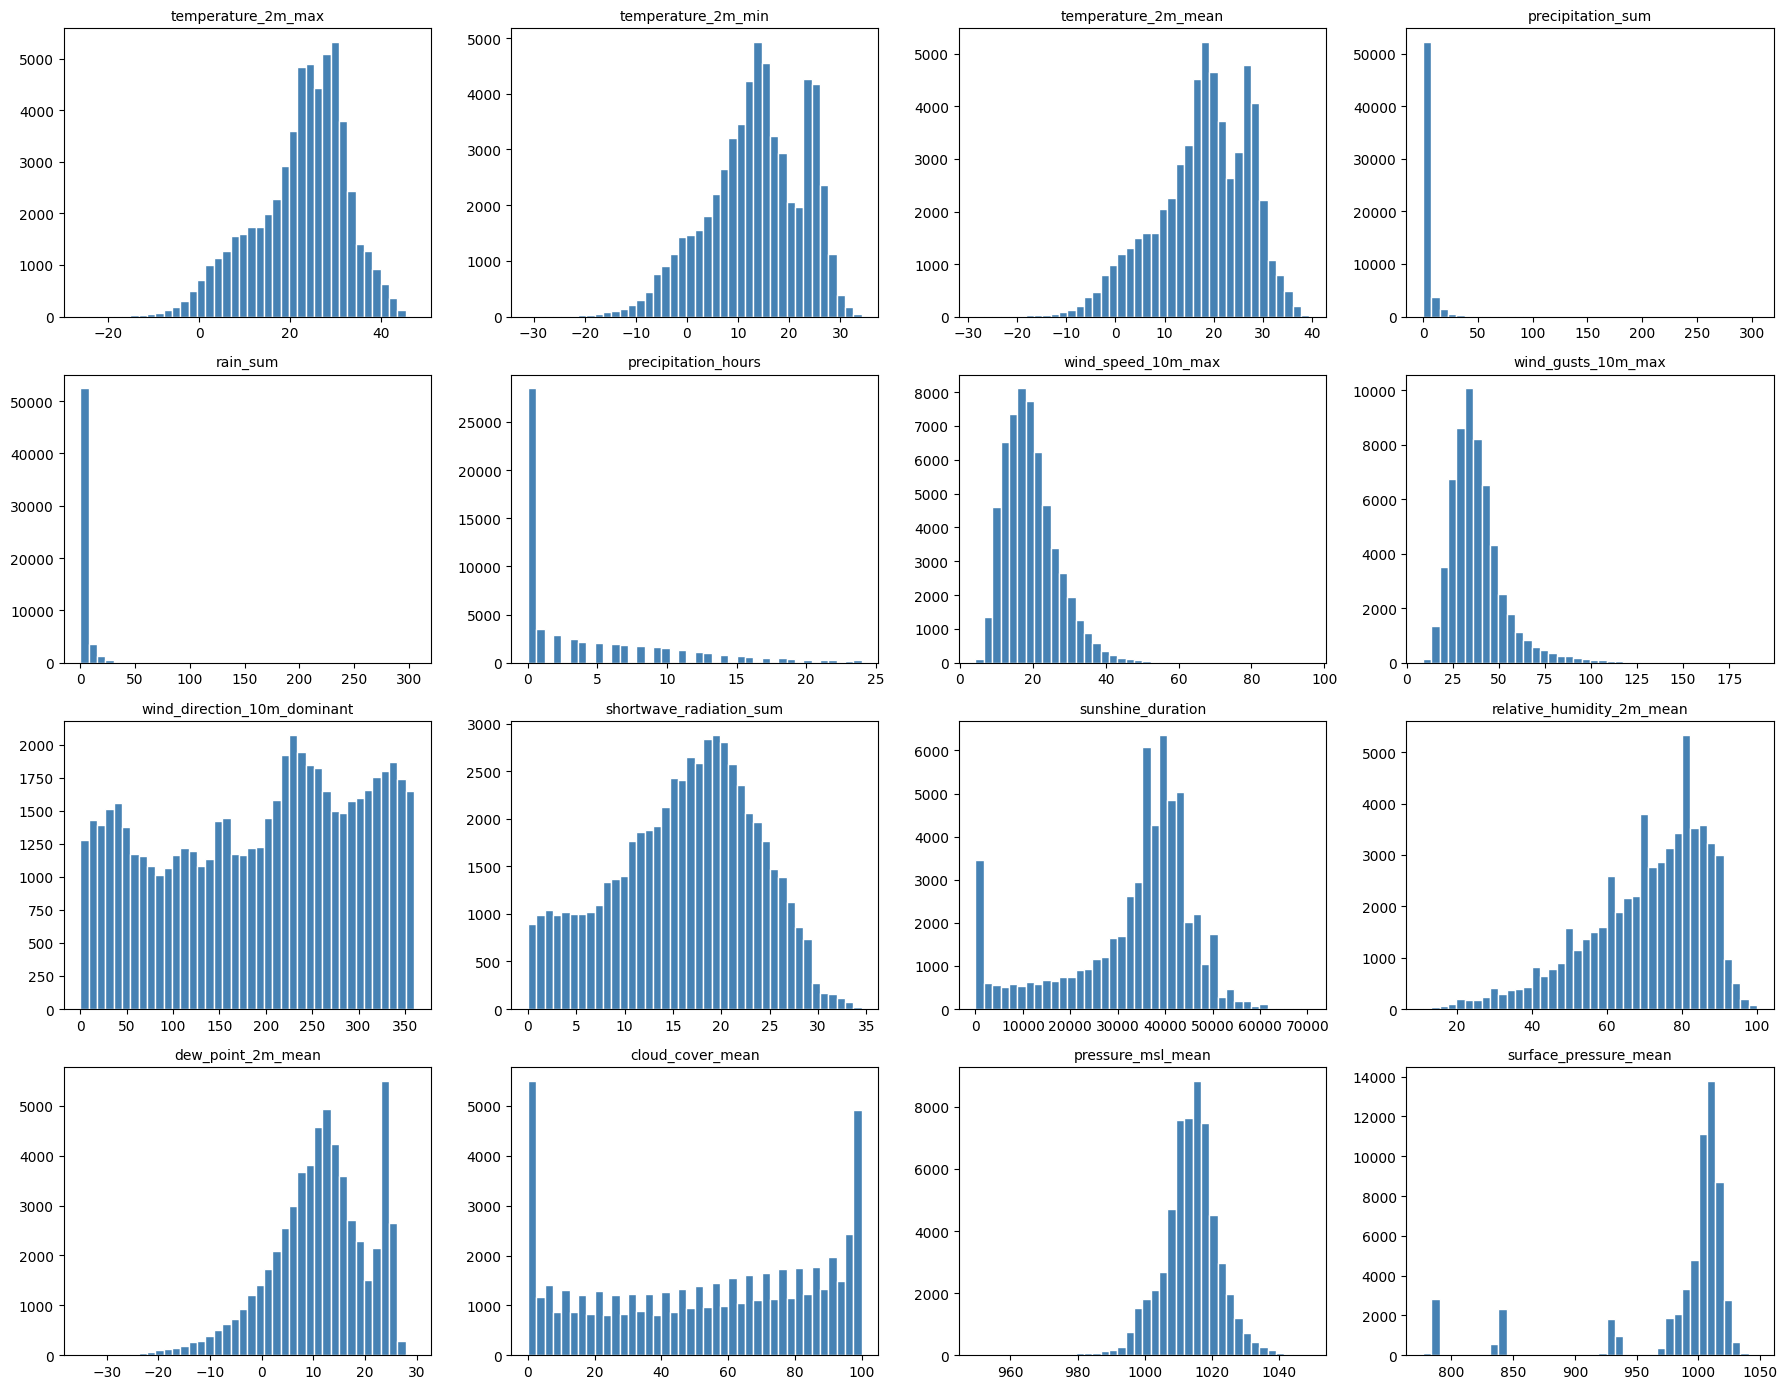

In [22]:
hist_cols = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
             "precipitation_sum", "rain_sum", "precipitation_hours",
             "wind_speed_10m_max", "wind_gusts_10m_max", "wind_direction_10m_dominant",
             "shortwave_radiation_sum", "sunshine_duration", "relative_humidity_2m_mean",
             "dew_point_2m_mean", "cloud_cover_mean", "pressure_msl_mean",
             "surface_pressure_mean"]

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, hist_cols):
    ax.hist(eda[col], bins=40, color="steelblue", edgecolor="white")
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

Precipitation, rain, wind speed and wind gusts are strongly right-skewed, with most days near the low end and a few extreme days. Humidity and dew point are left-skewed. Temperature has several peaks because cities with different climates are pooled together. Cloud cover is U-shaped, with many clear and fully overcast days. Surface pressure has separate clusters, which likely come from the higher-altitude cities.

## 6.2

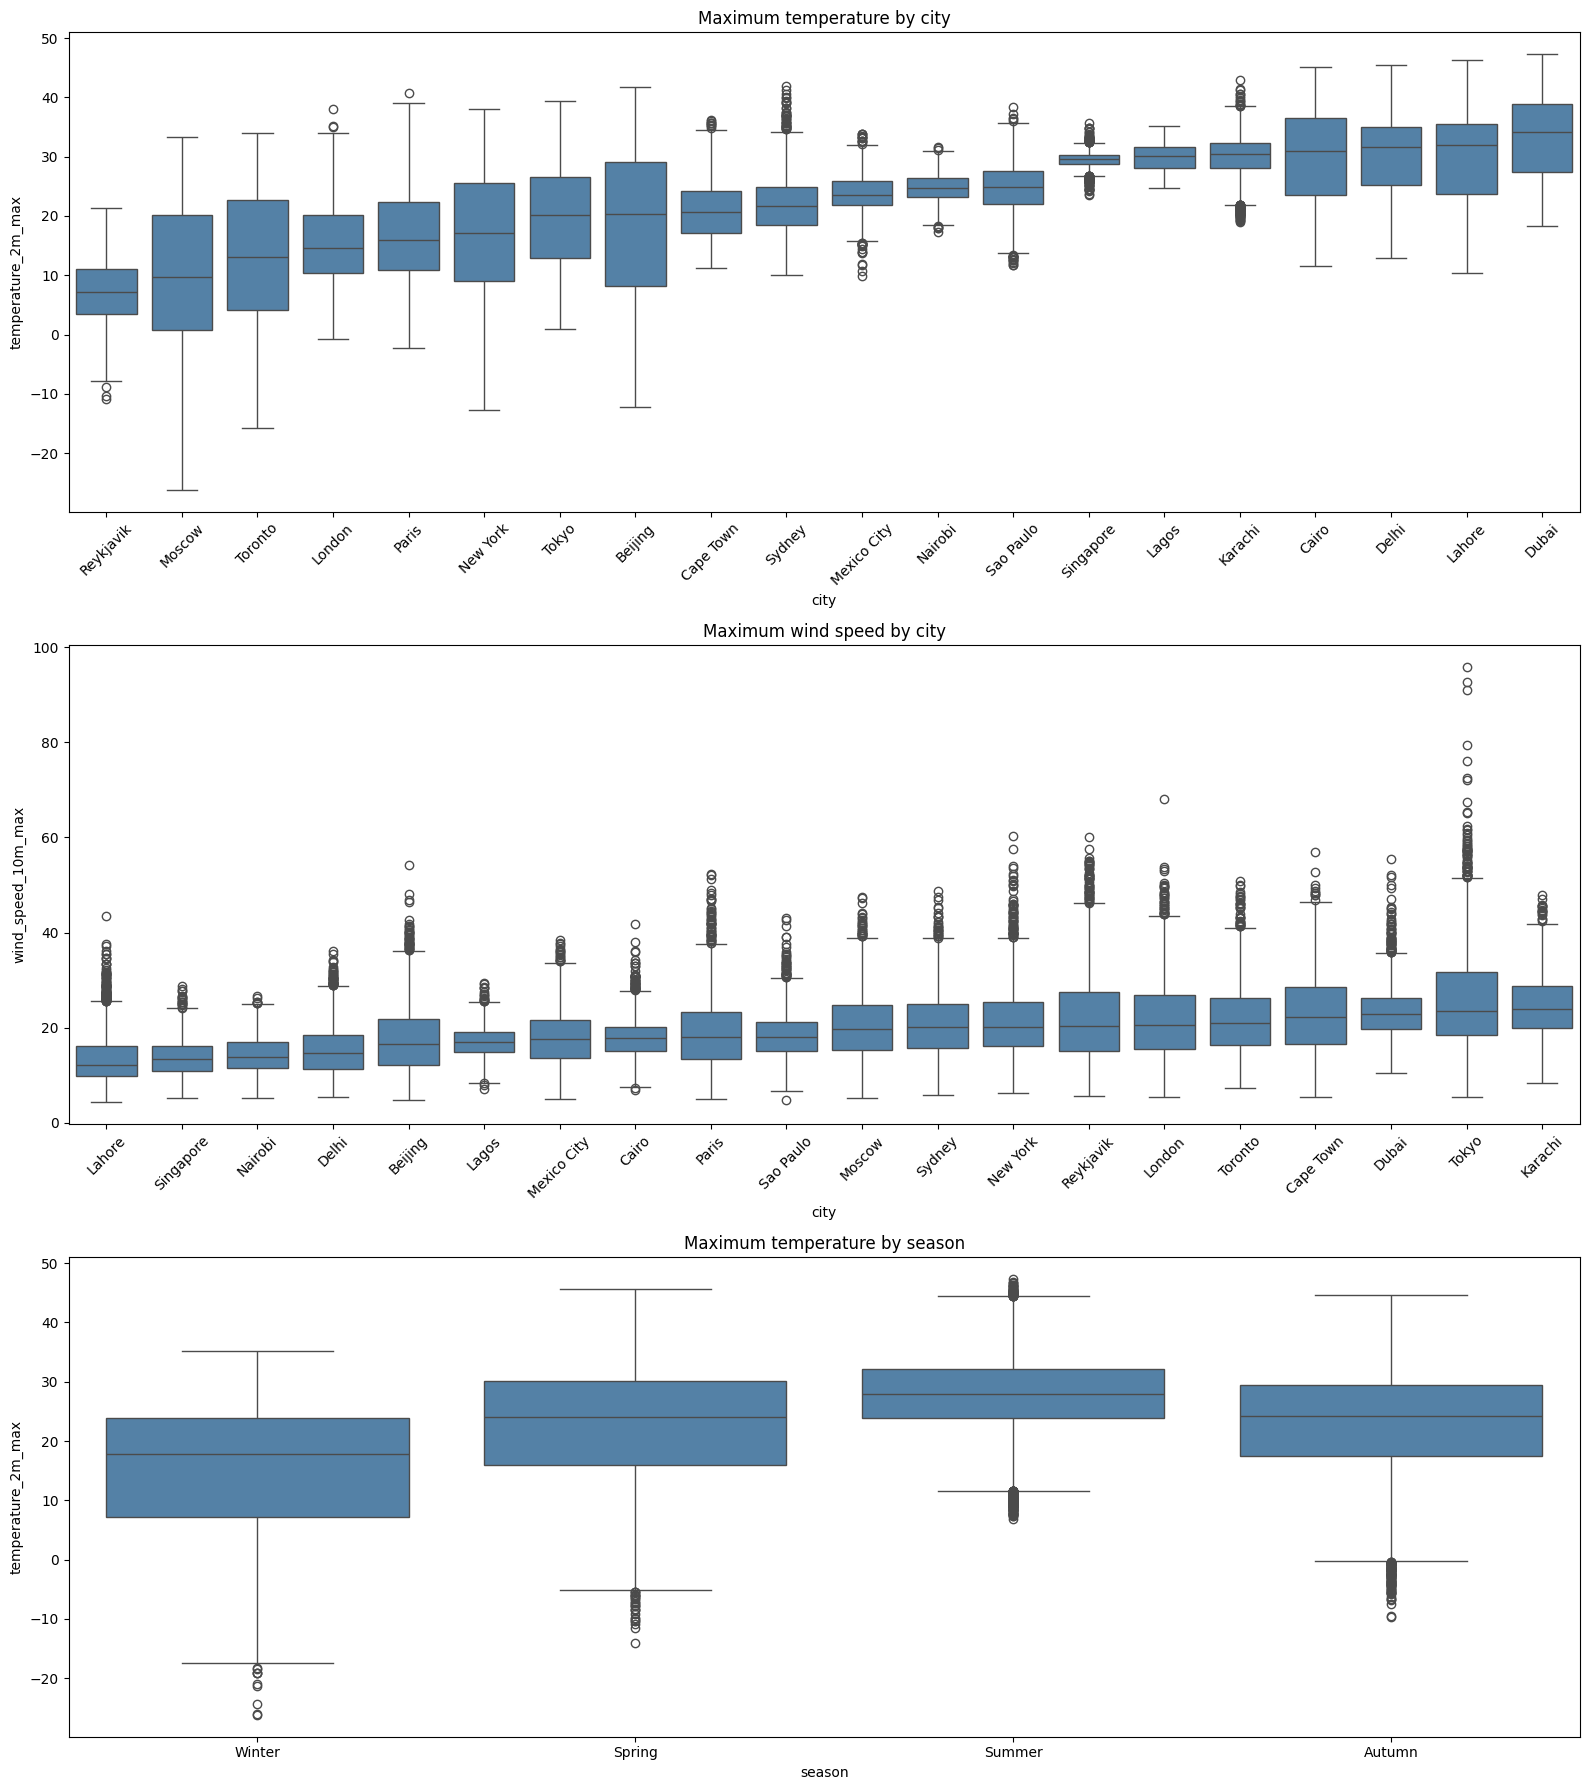

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(16, 18))

order = eda.groupby("city")["temperature_2m_max"].median().sort_values().index
sns.boxplot(data=eda, x="city", y="temperature_2m_max", order=order, ax=axes[0], color="steelblue")
axes[0].set_title("Maximum temperature by city")
axes[0].tick_params(axis="x", rotation=45)

order = eda.groupby("city")["wind_speed_10m_max"].median().sort_values().index
sns.boxplot(data=eda, x="city", y="wind_speed_10m_max", order=order, ax=axes[1], color="steelblue")
axes[1].set_title("Maximum wind speed by city")
axes[1].tick_params(axis="x", rotation=45)

sns.boxplot(data=eda, x="season", y="temperature_2m_max",
            order=["Winter", "Spring", "Summer", "Autumn"], ax=axes[2], color="steelblue")
axes[2].set_title("Maximum temperature by season")

plt.tight_layout()
plt.show()

Compared maximum temperature and maximum wind speed across cities, and maximum temperature across seasons, using box plots of the complete training data.

Temperature differs a lot between cities: Reykjavik is the coldest and Dubai the hottest. Wind speed has many high points in every city, and Tokyo has the most extreme values.

## 6.3

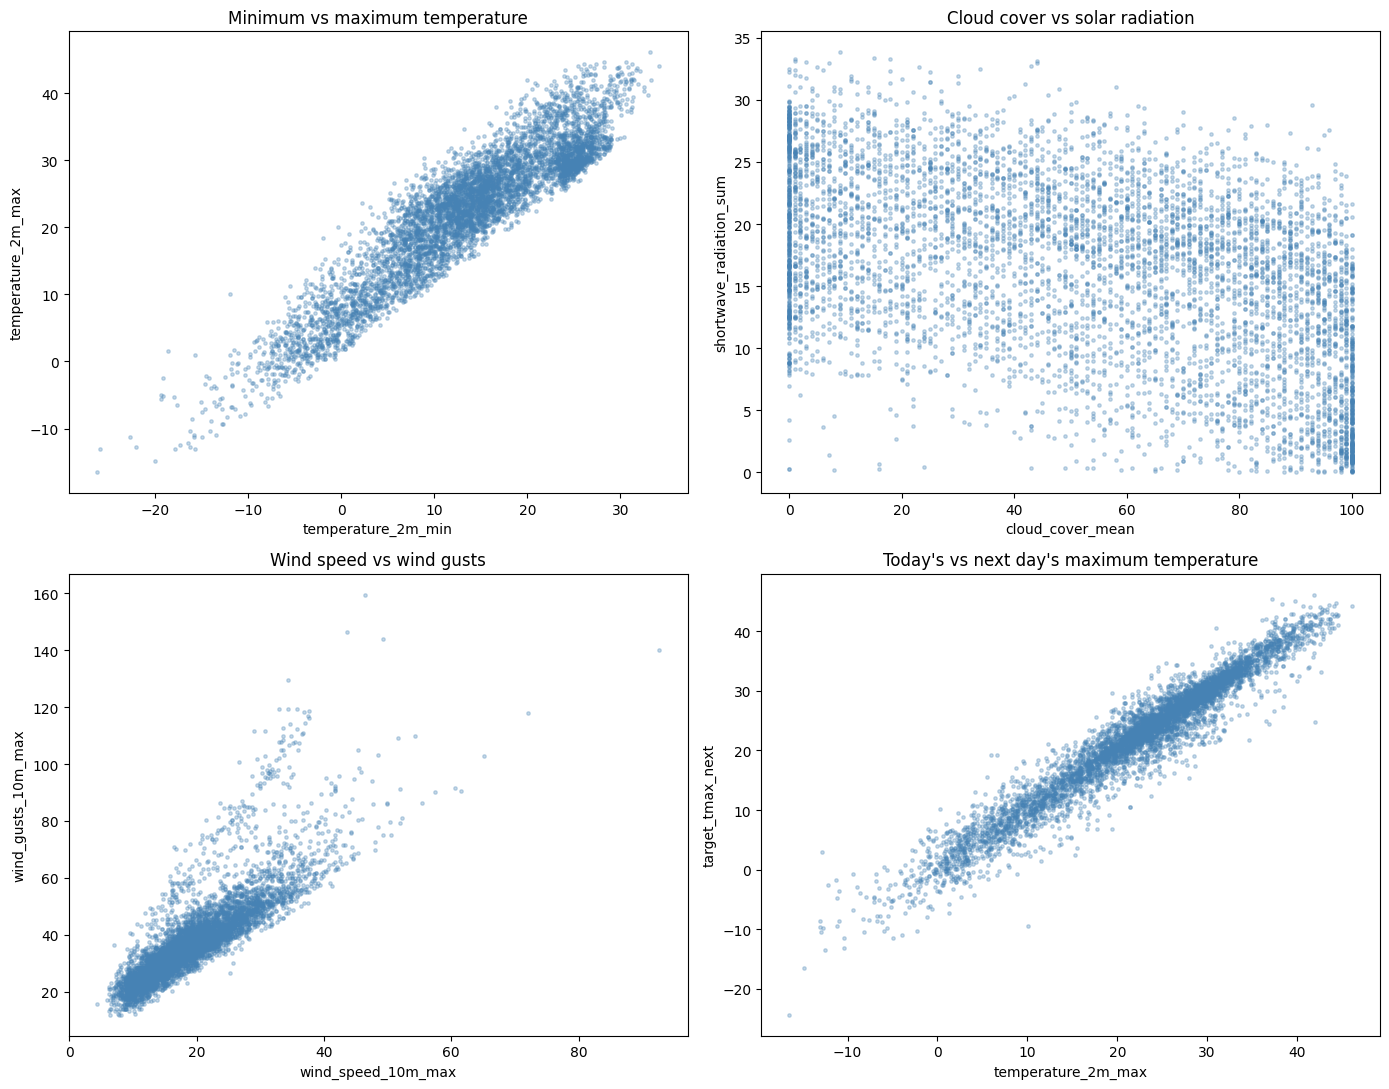

Minimum vs maximum temperature: r = 0.92
Cloud cover vs solar radiation: r = -0.48
Wind speed vs wind gusts: r = 0.84
Today's vs next day's maximum temperature: r = 0.97


In [25]:
sample = eda.sample(6000, random_state=SEED)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
pairs = [("temperature_2m_min", "temperature_2m_max", "Minimum vs maximum temperature"),
         ("cloud_cover_mean", "shortwave_radiation_sum", "Cloud cover vs solar radiation"),
         ("wind_speed_10m_max", "wind_gusts_10m_max", "Wind speed vs wind gusts"),
         ("temperature_2m_max", "target_tmax_next", "Today's vs next day's maximum temperature")]

for ax, (x, y, title) in zip(axes.flat, pairs):
    ax.scatter(sample[x], sample[y], s=6, alpha=0.3, color="steelblue")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(title)
plt.tight_layout()
plt.show()

for x, y, title in pairs:
    print(f"{title}: r = {eda[x].corr(eda[y]):.2f}")

Minimum and maximum temperature are strongly related (r = 0.92), and wind speed and gusts too (r = 0.84). Cloud cover and solar radiation have a moderate negative relationship (r = -0.48), because radiation also depends on season and latitude. Today's and next day's maximum temperature are almost linearly related (r = 0.97)

## 6.4

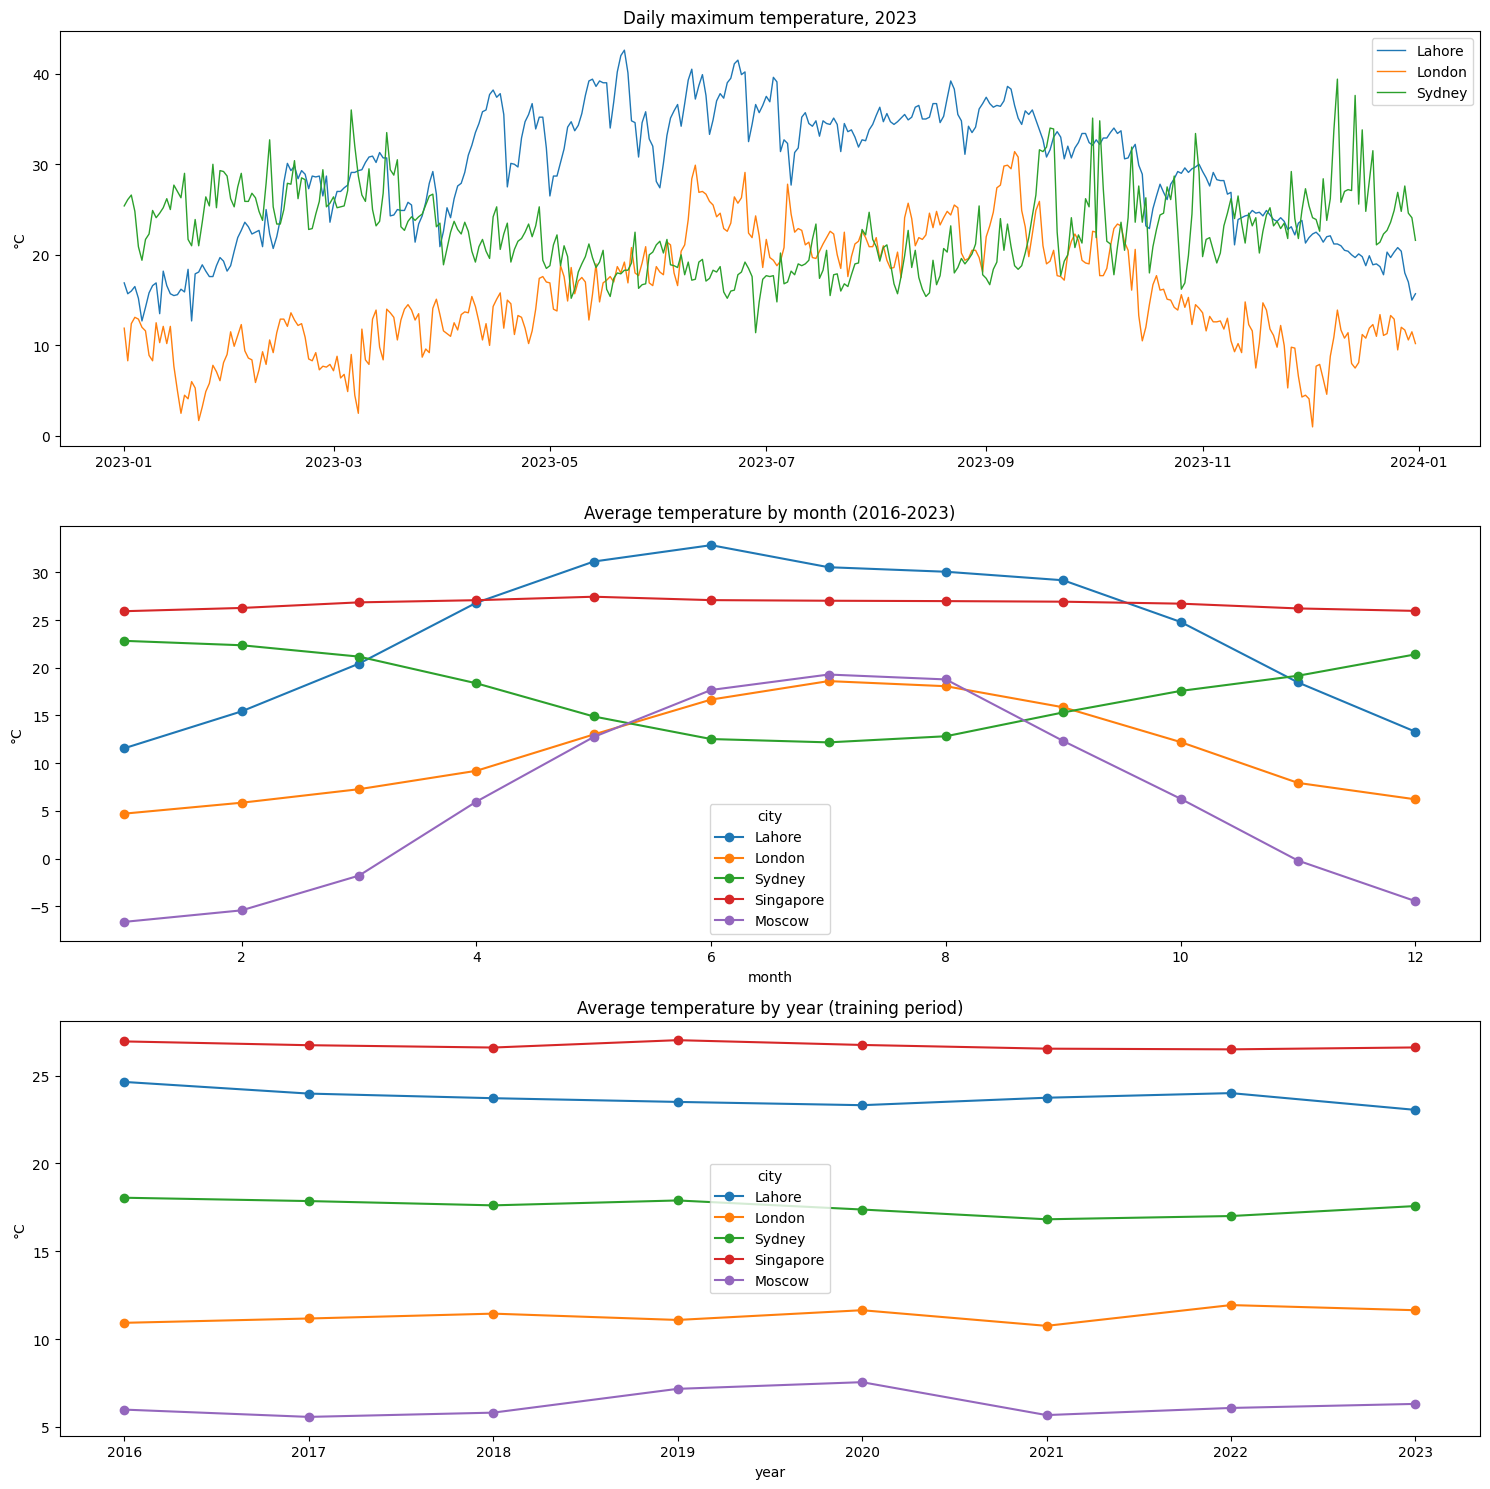

In [26]:
cities_plot = ["Lahore", "London", "Sydney", "Singapore", "Moscow"]
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

sub = eda[(eda["year"] == 2023) & (eda["city"].isin(["Lahore", "London", "Sydney"]))]
for city, g in sub.groupby("city"):
    axes[0].plot(g["date"], g["temperature_2m_max"], label=city, linewidth=1)
axes[0].set_title("Daily maximum temperature, 2023")
axes[0].set_ylabel("°C")
axes[0].legend()

monthly = eda.groupby(["month", "city"])["temperature_2m_mean"].mean().unstack()
monthly[cities_plot].plot(ax=axes[1], marker="o")
axes[1].set_title("Average temperature by month (2016-2023)")
axes[1].set_xlabel("month")
axes[1].set_ylabel("°C")

yearly = eda.groupby(["year", "city"])["temperature_2m_mean"].mean().unstack()
yearly[cities_plot].plot(ax=axes[2], marker="o")
axes[2].set_title("Average temperature by year (training period)")
axes[2].set_ylabel("°C")

plt.tight_layout()
plt.show()

Plotted daily maximum temperature for 2023 (Lahore, London, Sydney), monthly average temperature across the training years, and yearly average temperature, to look at short-term, seasonal and long-term patterns.

## 6.5

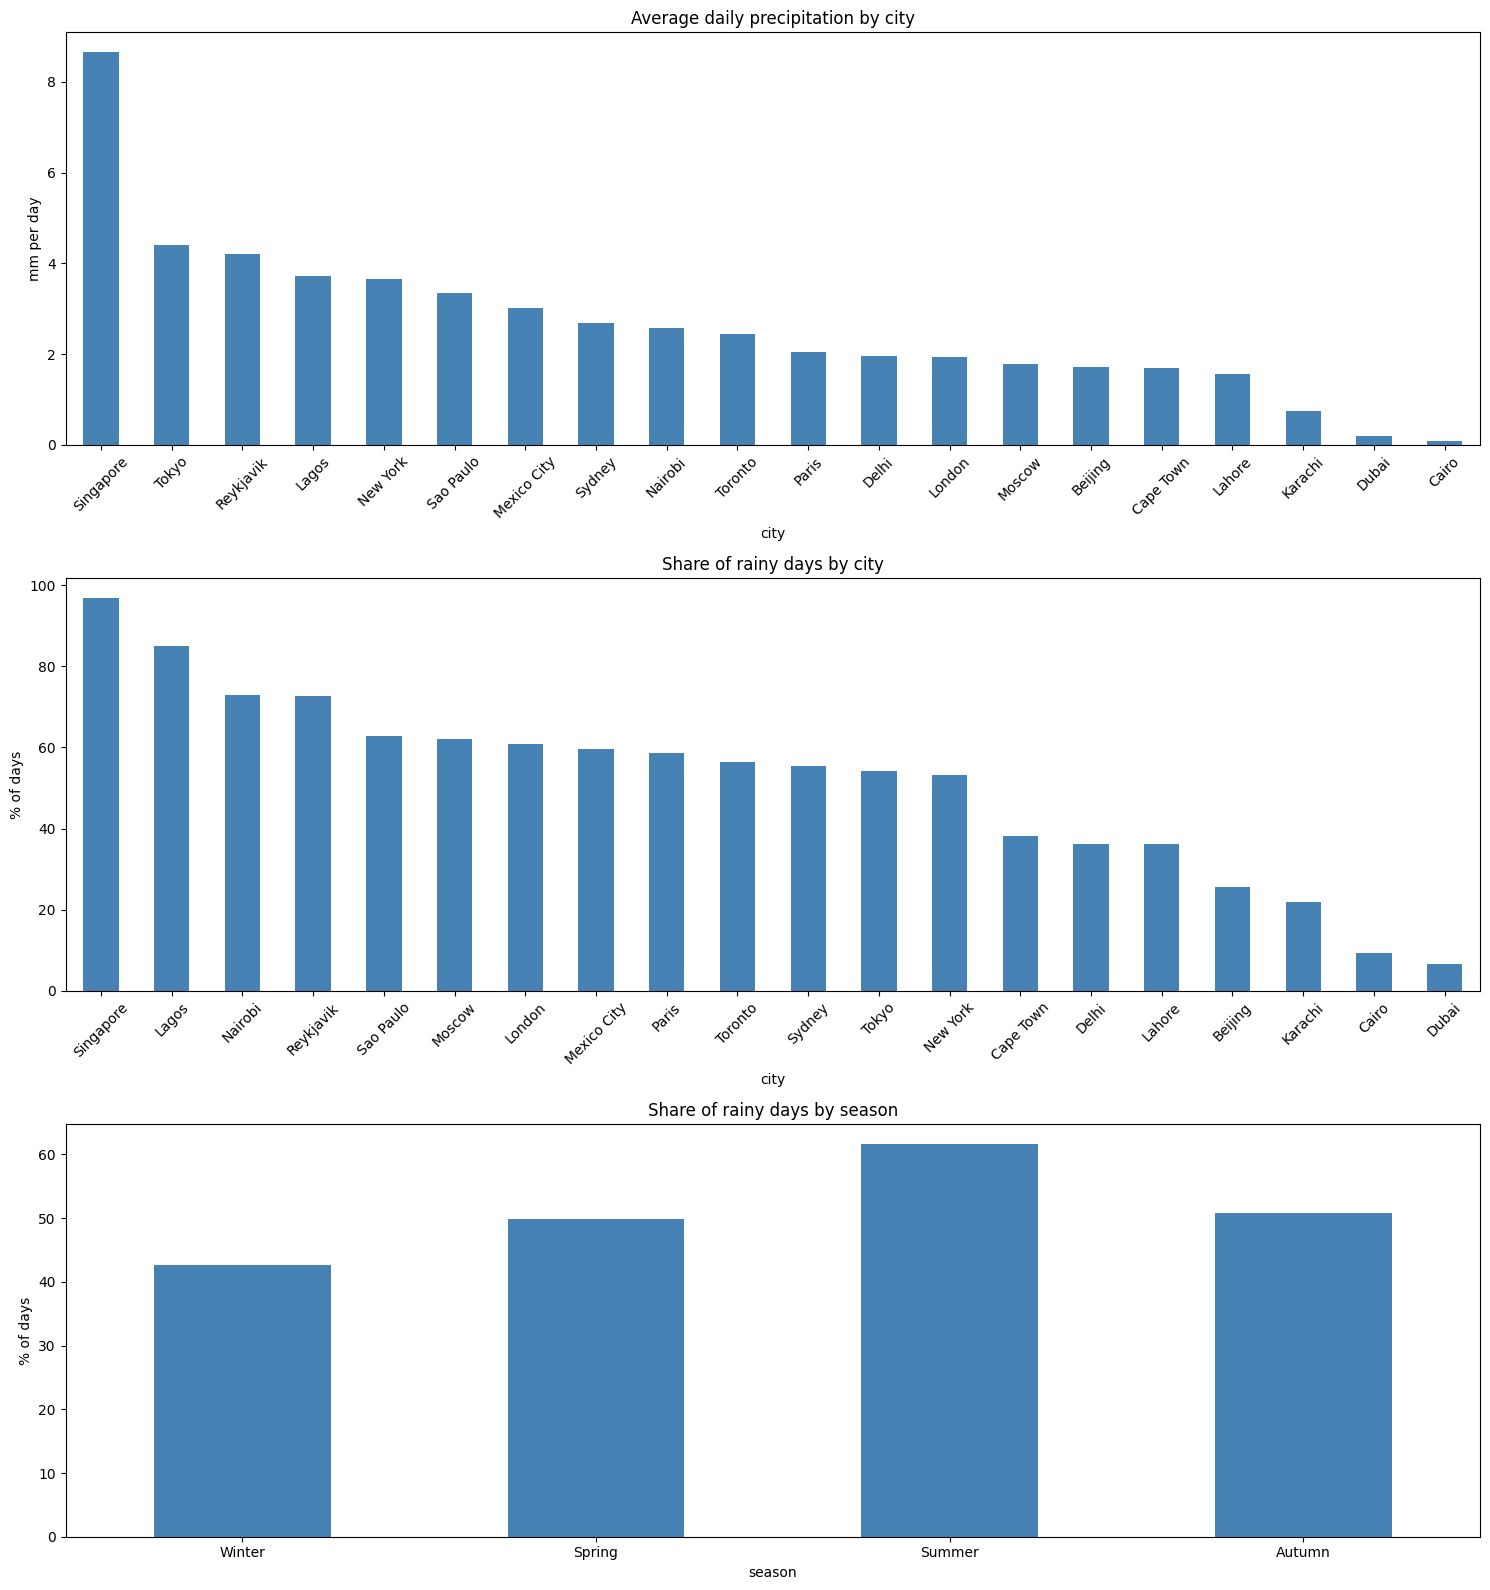

city
Singapore      96.9
Lagos          85.0
Nairobi        72.9
Reykjavik      72.7
Sao Paulo      62.7
Moscow         62.1
London         60.9
Mexico City    59.7
Paris          58.7
Toronto        56.4
Sydney         55.4
Tokyo          54.3
New York       53.3
Cape Town      38.2
Delhi          36.3
Lahore         36.1
Beijing        25.6
Karachi        21.9
Cairo           9.4
Dubai           6.7
Name: is_rainy, dtype: float64


In [27]:
fig, axes = plt.subplots(3, 1, figsize=(15, 16))

prec = eda.groupby("city")["precipitation_sum"].mean().sort_values(ascending=False)
prec.plot(kind="bar", ax=axes[0], color="steelblue", rot=45)
axes[0].set_title("Average daily precipitation by city")
axes[0].set_ylabel("mm per day")
rainy = (eda.groupby("city")["is_rainy"].mean() * 100).sort_values(ascending=False)
rainy.plot(kind="bar", ax=axes[1], color="steelblue", rot=45)
axes[1].set_title("Share of rainy days by city")
axes[1].set_ylabel("% of days")

season_rain = (eda.groupby("season")["is_rainy"].mean() * 100).reindex(["Winter", "Spring", "Summer", "Autumn"])
season_rain.plot(kind="bar", ax=axes[2], color="steelblue", rot=0)
axes[2].set_title("Share of rainy days by season")
axes[2].set_ylabel("% of days")

plt.tight_layout()
plt.show()

print(rainy.round(1))

 Compared average daily precipitation and the share of rainy days across cities, and the share of rainy days across seasons, using the complete training data.

Singapore is the wettest city, with rain on almost every day, while Dubai and Cairo are the driest. The share of rainy days ranges from 6.7% to 96.9% between cities, even though the overall split is nearly balanced.

## 6.6

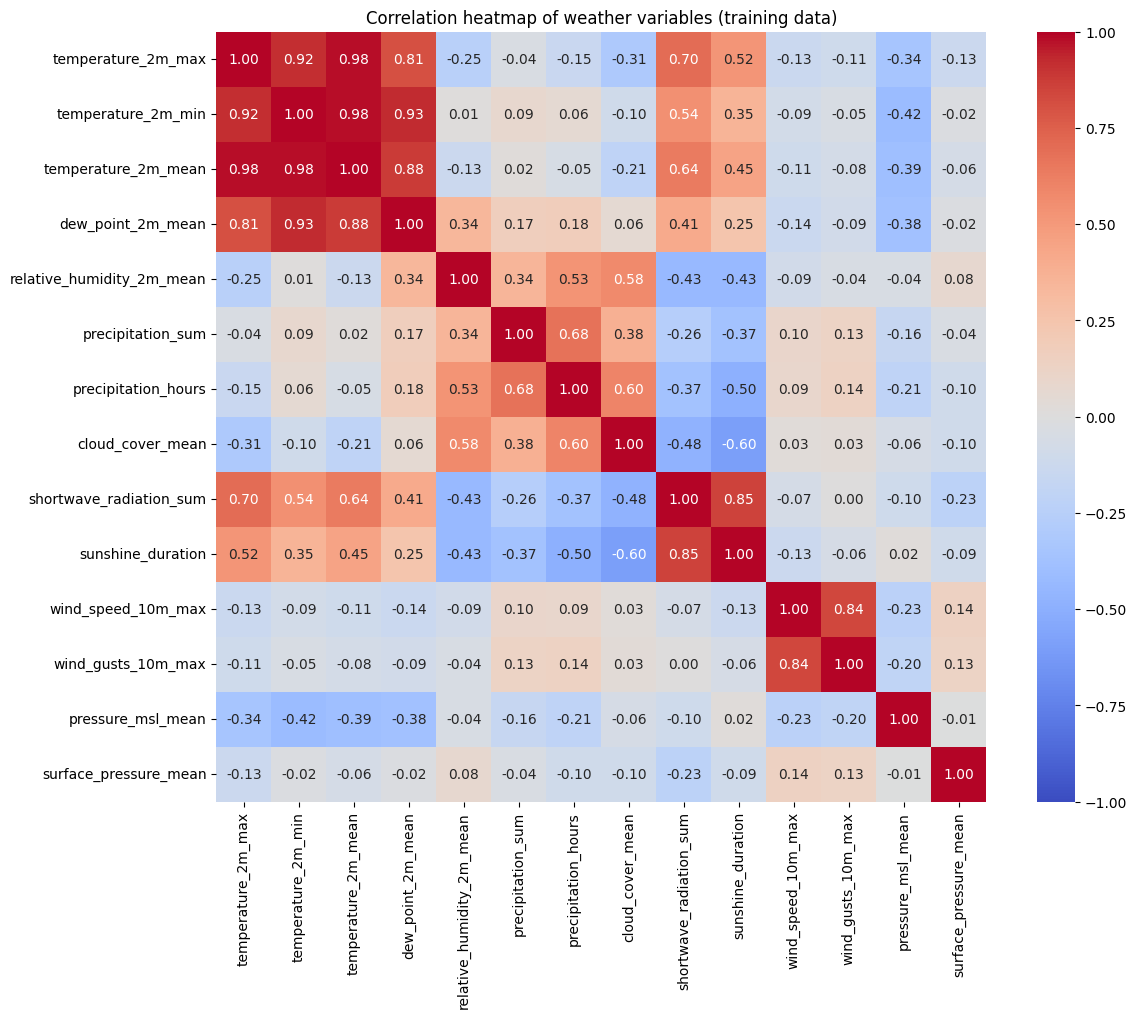

temperature_2m_max  temperature_2m_mean    0.98
temperature_2m_min  temperature_2m_mean    0.98
                    dew_point_2m_mean      0.93
temperature_2m_max  temperature_2m_min     0.92
dtype: float64


In [28]:
corr_cols = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
             "dew_point_2m_mean", "relative_humidity_2m_mean", "precipitation_sum",
             "precipitation_hours", "cloud_cover_mean", "shortwave_radiation_sum",
             "sunshine_duration", "wind_speed_10m_max", "wind_gusts_10m_max",
             "pressure_msl_mean", "surface_pressure_mean"]

corr = eda[corr_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap of weather variables (training data)")
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.9].sort_values(ascending=False).round(2))

Computed the correlation between 14 numerical weather variables on the training data and plotted it as a heatmap.Left out `rain_sum` (almost the same as precipitation), wind direction (a circular angle) and weather code (a category).

## 6.7

Unmapped rows: 0
               cities  mean_temp  temp_std  mean_precip  rainy_pct  mean_wind  \
region                                                                          
Africa              4      21.50      5.44         2.03      51.37      17.95   
Asia                7      22.51      8.94         2.75      39.69      19.17   
Europe              4       8.70      7.90         2.50      63.60      20.84   
North America       3      12.89      8.60         3.04      56.43      20.32   
Oceania             1      17.52      4.33         2.69      55.36      20.81   
South America       1      19.28      3.27         3.35      62.68      18.30   

               mean_humidity  
region                        
Africa                 69.47  
Asia                   66.45  
Europe                 77.65  
North America          67.89  
Oceania                72.99  
South America          81.14  


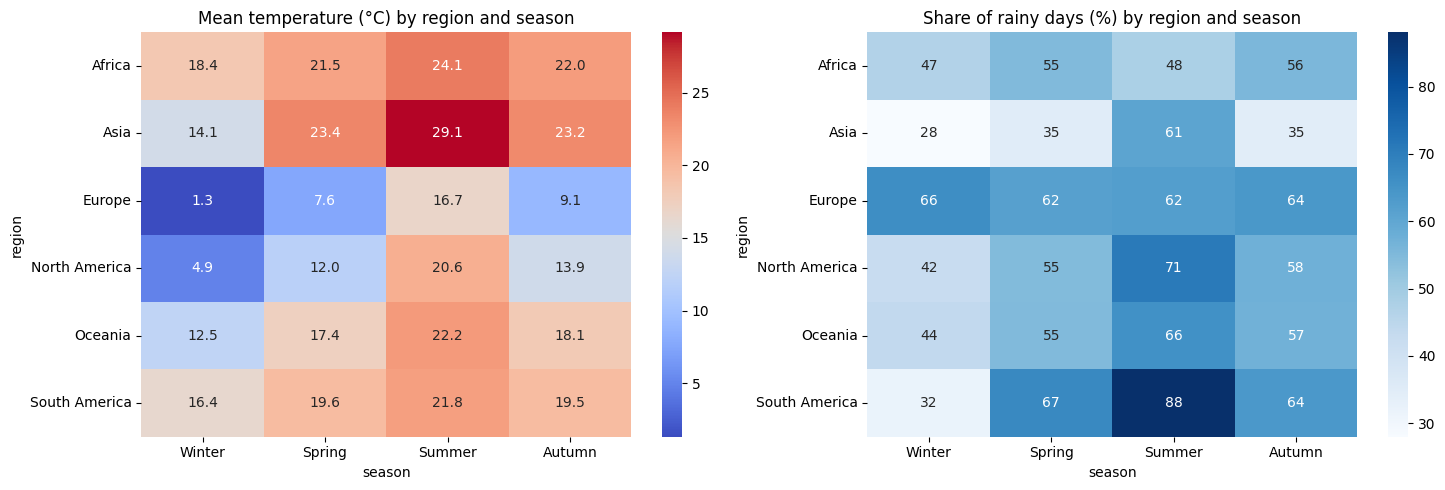

In [29]:
region_map = {"Pakistan": "Asia", "India": "Asia", "Japan": "Asia", "China": "Asia",
              "Singapore": "Asia", "UAE": "Asia",
              "Egypt": "Africa", "Kenya": "Africa", "Nigeria": "Africa", "South Africa": "Africa",
              "UK": "Europe", "France": "Europe", "Russia": "Europe", "Iceland": "Europe",
              "USA": "North America", "Canada": "North America", "Mexico": "North America",
              "Brazil": "South America", "Australia": "Oceania"}
eda["region"] = eda["country"].map(region_map)
print("Unmapped rows:", eda["region"].isnull().sum())

summary = eda.groupby("region").agg(
    cities=("city", "nunique"),
    mean_temp=("temperature_2m_mean", "mean"),
    temp_std=("temperature_2m_mean", "std"),
    mean_precip=("precipitation_sum", "mean"),
    rainy_pct=("is_rainy", lambda s: s.mean() * 100),
    mean_wind=("wind_speed_10m_max", "mean"),
    mean_humidity=("relative_humidity_2m_mean", "mean")).round(2)
print(summary)

season_order = ["Winter", "Spring", "Summer", "Autumn"]
temp_tab = eda.pivot_table(index="region", columns="season",
                           values="temperature_2m_mean", aggfunc="mean")[season_order]
rain_tab = eda.pivot_table(index="region", columns="season",
                           values="is_rainy", aggfunc="mean")[season_order] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(temp_tab, annot=True, fmt=".1f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Mean temperature (°C) by region and season")
sns.heatmap(rain_tab, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Share of rainy days (%) by region and season")
plt.tight_layout()
plt.show()

I grouped the 20 cities into six continents and compared their average temperature, rainfall, share of rainy days, wind and humidity, then looked at temperature and rainy-day share by region and season.

#Section 7: Skewness Analysis and Treatment


## 7.1 and 7.2:

In [30]:
skew_cols = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
             "precipitation_sum", "rain_sum", "precipitation_hours",
             "wind_speed_10m_max", "wind_gusts_10m_max", "shortwave_radiation_sum",
             "sunshine_duration", "relative_humidity_2m_mean", "dew_point_2m_mean",
             "cloud_cover_mean", "pressure_msl_mean", "surface_pressure_mean"]

skew_table = pd.DataFrame({"skewness": train_imp[skew_cols].skew().round(2)})
skew_table["type"] = np.select(
    [skew_table["skewness"] >= 1, skew_table["skewness"] >= 0.5,
     skew_table["skewness"] <= -1, skew_table["skewness"] <= -0.5],
    ["strongly positive", "moderately positive",
     "strongly negative", "moderately negative"],
    default="approximately symmetric")
skew_table.sort_values("skewness", ascending=False)

,skewness,type
rain_sum,8.11,strongly positive
precipitation_sum,7.91,strongly positive
wind_gusts_10m_max,1.88,strongly positive
precipitation_hours,1.49,strongly positive
wind_speed_10m_max,1.10,strongly positive
cloud_cover_mean,-0.19,approximately symmetric
shortwave_radiation_sum,-0.29,approximately symmetric
pressure_msl_mean,-0.43,approximately symmetric
temperature_2m_min,-0.48,approximately symmetric
temperature_2m_mean,-0.59,moderately negative


Calculated the skewness of 15 numerical variables on the training data after imputation. Left out wind direction (a circular angle), weather code (a category) and daylight duration (fixed by latitude and date).



## 7.3 to 7.5

                variable transform  skew_before  skew_after
0      precipitation_sum     log1p         7.91        1.39
1    precipitation_hours      sqrt         1.49        0.63
2     wind_speed_10m_max     log1p         1.10        0.00
3     wind_gusts_10m_max     log1p         1.88        0.31
4      sunshine_duration    square        -1.10        0.02
5  surface_pressure_mean    square        -2.33       -2.25


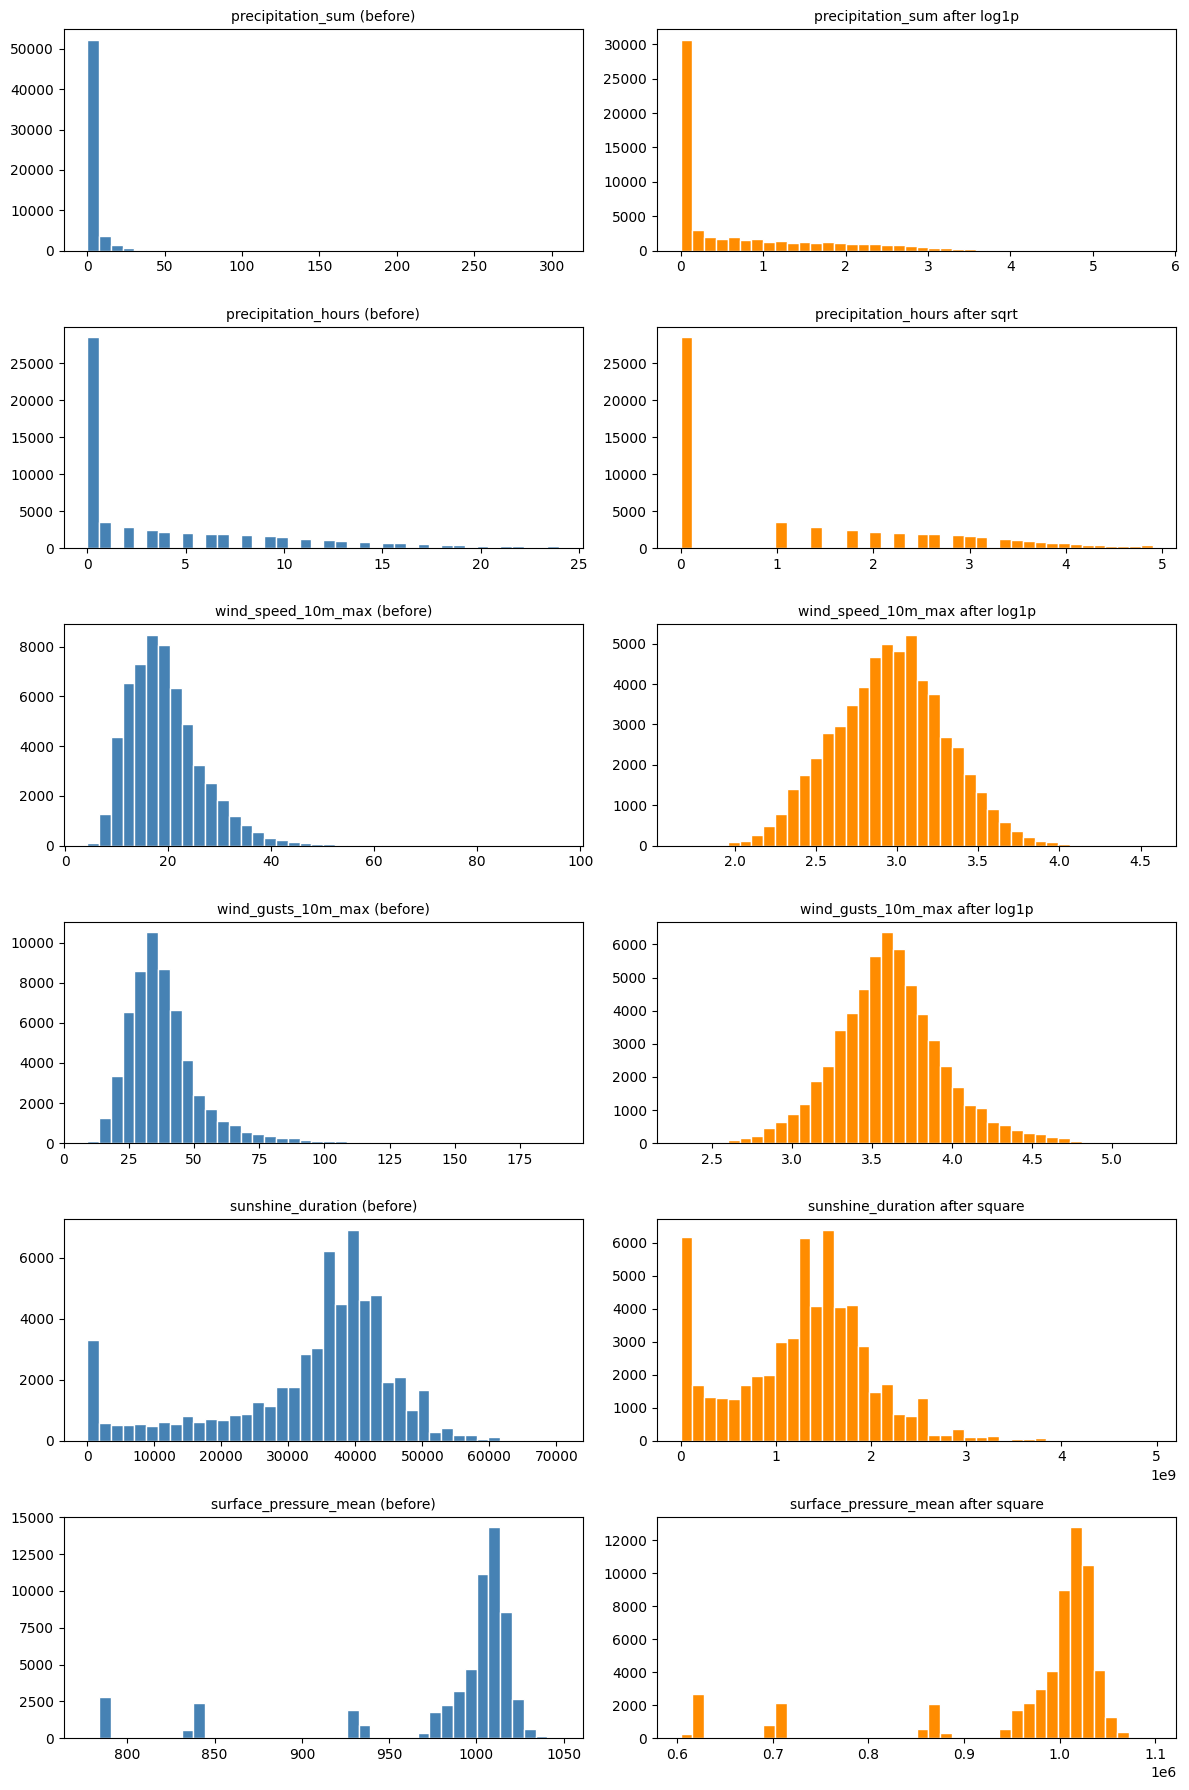

In [31]:
tests = {"precipitation_sum":     ("log1p",  np.log1p),
         "precipitation_hours":   ("sqrt",   np.sqrt),
         "wind_speed_10m_max":    ("log1p",  np.log1p),
         "wind_gusts_10m_max":    ("log1p",  np.log1p),
         "sunshine_duration":     ("square", np.square),
         "surface_pressure_mean": ("square", np.square)}

rows = []
for col, (name, fn) in tests.items():
    rows.append({"variable": col, "transform": name,
                 "skew_before": round(train_imp[col].skew(), 2),
                 "skew_after": round(fn(train_imp[col]).skew(), 2)})
print(pd.DataFrame(rows))

fig, axes = plt.subplots(len(tests), 2, figsize=(12, 3 * len(tests)))
for i, (col, (name, fn)) in enumerate(tests.items()):
    axes[i, 0].hist(train_imp[col], bins=40, color="steelblue", edgecolor="white")
    axes[i, 0].set_title(f"{col} (before)", fontsize=10)
    axes[i, 1].hist(fn(train_imp[col]), bins=40, color="darkorange", edgecolor="white")
    axes[i, 1].set_title(f"{col} after {name}", fontsize=10)
plt.tight_layout()
plt.show()

I tested a transformation on the six most skewed variables and compared skewness and histograms before and after. I used log1p for precipitation and wind (log1p keeps zero values valid), sqrt for precipitation hours, and squaring for the negatively skewed variables.


## 7.4

In [32]:
final_transforms = {"precipitation_sum": np.log1p, "precipitation_sum_lag1": np.log1p,
                    "precipitation_hours": np.sqrt,
                    "wind_speed_10m_max": np.log1p, "wind_speed_10m_max_lag1": np.log1p,
                    "wind_gusts_10m_max": np.log1p}

def apply_transforms(df):
    out = df.copy()
    for col, fn in final_transforms.items():
        out[col] = fn(out[col])
    return out

train_tr = apply_transforms(train_imp)
test_tr = apply_transforms(test_imp)

check_cols = list(final_transforms)
print("Missing values after transform:",
      train_tr[check_cols].isnull().sum().sum() + test_tr[check_cols].isnull().sum().sum())
print(pd.DataFrame({
    "skew_train_before": train_imp[check_cols].skew().round(2),
    "skew_train_after": train_tr[check_cols].skew().round(2),
    "skew_test_after": test_tr[check_cols].skew().round(2)}))

Missing values after transform: 0
                         skew_train_before  skew_train_after  skew_test_after
precipitation_sum                     7.91              1.39             1.39
precipitation_sum_lag1                8.21              1.44             1.42
precipitation_hours                   1.49              0.63             0.65
wind_speed_10m_max                    1.10              0.00             0.01
wind_speed_10m_max_lag1               1.10              0.00             0.01
wind_gusts_10m_max                    1.88              0.31             0.06


There were no missing values after the transformation. Skewness in the training set dropped (for example precipitation from 7.91 to 1.39 and wind speed from 1.10 to 0.00), and the test set shows almost the same values, so the transformation works equally on unseen data.

## 7.6

I transformed only the variables where the transformation clearly improved the distribution, not every skewed feature.

Wind speed and gusts (log1p) became almost symmetric, and precipitation and precipitation hours improved a lot, although both keep a spike of dry days at zero that no transformation can remove. I did not transform sunshine duration, because its skewness became close to zero but its histogram stayed uneven with a spike at zero. I also did not transform surface pressure, because its skewness did not change and comes from the altitude of a few cities, which the city encoding already captures.

# Section 8: Outlier Detection and Analysis


## 8.1 and 8.2

In [33]:
out_cols = ["temperature_2m_max", "precipitation_sum", "wind_speed_10m_max",
            "wind_gusts_10m_max", "shortwave_radiation_sum", "pressure_msl_mean"]

def iqr_flag(df, col):
    q1 = df.groupby("city")[col].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby("city")[col].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)

def z_flag(df, col):
    mean = df.groupby("city")[col].transform("mean")
    std = df.groupby("city")[col].transform("std")
    return ((df[col] - mean) / std).abs() > 3

flags_iqr = pd.DataFrame({c: iqr_flag(train_imp, c) for c in out_cols})
flags_z = pd.DataFrame({c: z_flag(train_imp, c) for c in out_cols})

comparison = pd.DataFrame({
    "iqr_flagged": flags_iqr.sum(),
    "zscore_flagged": flags_z.sum(),
    "both_methods": (flags_iqr & flags_z).sum(),
    "either_method": (flags_iqr | flags_z).sum()})
comparison["iqr_pct"] = (comparison["iqr_flagged"] / len(train_imp) * 100).round(2)
comparison["zscore_pct"] = (comparison["zscore_flagged"] / len(train_imp) * 100).round(2)
comparison

,iqr_flagged,zscore_flagged,both_methods,either_method,iqr_pct,zscore_pct
temperature_2m_max,288,114,109,293,0.49,0.20
precipitation_sum,7629,1124,1124,7629,13.06,1.92
wind_speed_10m_max,1004,454,454,1004,1.72,0.78
wind_gusts_10m_max,1171,499,499,1171,2.00,0.85
shortwave_radiation_sum,404,150,145,409,0.69,0.26
pressure_msl_mean,681,181,181,681,1.17,0.31


I applied the IQR rule (beyond 1.5 × IQR) and the Z-score rule (beyond 3 standard deviations) to six variables on the training data, in original units. Both were calculated separately for each city, because a normal day in one city can look extreme in another.

The IQR rule flagged more days than the Z-score rule for every variable, and most Z-score flags were also IQR flags.

## 8.3

In [34]:
both = flags_iqr & flags_z
print(both.groupby(train_imp["city"]).sum())
z_all = {c: (train_imp[c] - train_imp.groupby("city")[c].transform("mean"))
            / train_imp.groupby("city")[c].transform("std") for c in out_cols}

for col in out_cols:
    rows = train_imp.loc[both[col], ["city", "date", col]].copy()
    rows["city_median"] = train_imp.groupby("city")[col].transform("median")[both[col]]
    rows["z"] = z_all[col][both[col]].round(1)
    top = rows.loc[rows["z"].abs().sort_values(ascending=False).index].head(5)
    print(f"\n{col}: {both[col].sum()} flagged by both methods, 5 most extreme")
    print(top.to_string())
i = train_imp["precipitation_sum"].idxmax()
c = train_imp.loc[i, "city"]
context = train_imp[(train_imp["city"] == c) & (train_imp.index.to_series().between(i - 3, i + 3))]
print("\nWettest day and its neighbours:")
print(context[["city", "date", "precipitation_sum", "precipitation_hours", "weather_code"]].to_string())

             temperature_2m_max  precipitation_sum  wind_speed_10m_max  \
city                                                                     
Beijing                       0                 51                  23   
Cairo                         0                 20                  20   
Cape Town                     9                 60                  13   
Delhi                         0                 56                  25   
Dubai                         0                 26                  30   
Karachi                      10                 24                  14   
Lagos                         0                 47                  11   
Lahore                        0                 60                  45   
London                        3                 65                  22   
Mexico City                  14                 68                  14   
Moscow                        0                 64                  16   
Nairobi                       1       

I looked at the days flagged by both methods, with their city, date and value compared with the city's median, and at the days around the wettest day.

The most extreme days are consistent across variables and look like real events. The 304.9 mm day in Karachi has 24 precipitation hours, a heavy-rain weather code and very low radiation, with light rain on the days before and after. The extreme winds in Tokyo fall on dates that match major typhoons, and the low pressure in London matches a major storm. Singapore's temperature flags are exaggerated because its temperature varies very little. I found no sign of data errors.

## 8.4 and 8.5

Cap limits:
 precipitation_sum           68.4
precipitation_sum_lag1      67.6
wind_speed_10m_max          54.0
wind_speed_10m_max_lag1     54.0
wind_gusts_10m_max         121.6
dtype: float64

Train values capped: {'precipitation_sum': 59, 'precipitation_sum_lag1': 59, 'wind_speed_10m_max': 59, 'wind_speed_10m_max_lag1': 58, 'wind_gusts_10m_max': 59}
Test values capped : {'precipitation_sum': 13, 'precipitation_sum_lag1': 13, 'wind_speed_10m_max': 20, 'wind_speed_10m_max_lag1': 21, 'wind_gusts_10m_max': 5}
                    max_before  max_after  skew_before  skew_after_cap  \
precipitation_sum        304.9    68.4067         7.91            4.70   
wind_speed_10m_max        95.9    53.9581         1.10            1.01   
wind_gusts_10m_max       190.1   121.5810         1.88            1.77   

                    skew_after_cap_and_transform  
precipitation_sum                           1.38  
wind_speed_10m_max                         -0.01  
wind_gusts_10m_max                   

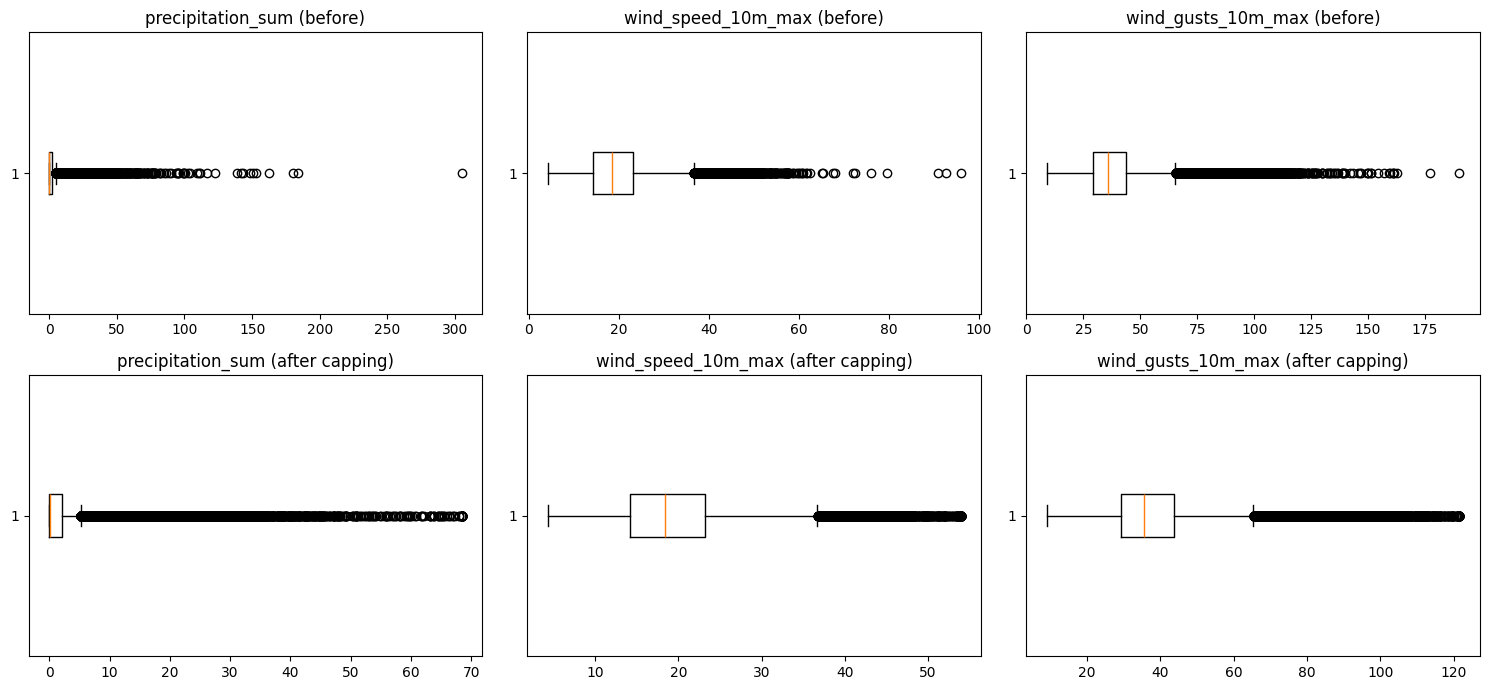

In [35]:
cap_cols = ["precipitation_sum", "precipitation_sum_lag1", "wind_speed_10m_max",
            "wind_speed_10m_max_lag1", "wind_gusts_10m_max"]
caps = {c: train_imp[c].quantile(0.999) for c in cap_cols}
print("Cap limits:\n", pd.Series(caps).round(1))

def cap_values(df):
    out = df.copy()
    for c, limit in caps.items():
        out[c] = out[c].clip(upper=limit)
    return out

train_cap, test_cap = cap_values(train_imp), cap_values(test_imp)
print("\nTrain values capped:", {c: int((train_imp[c] > caps[c]).sum()) for c in cap_cols})
print("Test values capped :", {c: int((test_imp[c] > caps[c]).sum()) for c in cap_cols})

train_tr = apply_transforms(train_cap)
test_tr = apply_transforms(test_cap)
show = ["precipitation_sum", "wind_speed_10m_max", "wind_gusts_10m_max"]
print(pd.DataFrame({"max_before": train_imp[show].max(), "max_after": train_cap[show].max(),
                    "skew_before": train_imp[show].skew().round(2),
                    "skew_after_cap": train_cap[show].skew().round(2),
                    "skew_after_cap_and_transform": train_tr[show].skew().round(2)}))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, c in enumerate(show):
    axes[0, j].boxplot(train_imp[c], vert=False)
    axes[0, j].set_title(f"{c} (before)")
    axes[1, j].boxplot(train_cap[c], vert=False)
    axes[1, j].set_title(f"{c} (after capping)")
plt.tight_layout()
plt.show()

The flagged days are real weather extremes, so I removed no rows. I capped the input variables precipitation, wind speed (with their lags) and wind gusts at their 99.9th percentile

The output shows the largest values dropping from 304.9 to 68.4 mm for precipitation and from 190.1 to 121.6 km/h for gusts. Skewness after capping and the Section 7 transformation is 1.38 for precipitation, -0.01 for wind speed and 0.30 for gusts.